In [2]:
# constants

#general strings
GEOM_COL_NAME = 'geometry'
PATH_COL_NAME = 'path'
TIF_SUFFIX = '.tif'
GEOJSON_SUFFIX = '.geojson'
CONST_CRS = "4326"
CRS_3857 = "3857"
# SUFFIX_FOR_TIF_FOLDER = "/*.TIF"
SUFFIX_FOR_TIF_FOLDER = "/*.tif"

LAYER_COL_NAME ='layer'

STR_MINX = 'minx'
STR_MINY = 'miny'
STR_MAXX = 'maxx'
STR_MAXY = 'maxy'

BUILDING_STR = "building"

In [3]:
# utils

import pandas as pd
import numpy as np
import rasterio
from rasterio.mask import mask
from rasterio.merge import merge
import geopandas as gpd
from shapely.geometry import box,Polygon
import glob
import warnings
from tqdm import tqdm
import pathlib
import os
import shutil

In [4]:
#|export


def calculate_buffer(
        gdf : gpd.GeoDataFrame , # buffer will be calculated for this geodataframe
        buffer_size : float , # buffer size in meters
        )->gpd.GeoDataFrame:
    """ 
    This function accepts a GeoDataFrame and a buffer size, processes the following steps:
    
    1. Finds the estimated UTM CRS for the GeoDataFrame's geographic extent.
    2. Reprojects the GeoDataFrame to the estimated UTM CRS.
    3. Calculates the buffer for each geometry in the GeoDataFrame using the specified buffer size.
    4. Reprojects the buffered GeoDataFrame back to the WGS84 (EPSG:4326) projection.
    
    Parameters:
    gdf (GeoDataFrame): The input GeoDataFrame with geometries in WGS84 (EPSG:4326) projection.
    buffer_size (float): The buffer size to apply to each geometry in the GeoDataFrame.
    
    Returns:
    GeoDataFrame: A new GeoDataFrame with buffered geometries reprojected back to WGS84 
    
    """
    
    estimated_utm = gdf.estimate_utm_crs() 
    gdf = gdf.to_crs(estimated_utm)

    gdf[GEOM_COL_NAME] = gdf.buffer(distance = buffer_size)

    gdf = gdf.to_crs(CONST_CRS)



In [5]:
#|export

def save_raster(
    img:np.ndarray , # ndarray image
    number_of_bands: int , #number of  bands
    transf:tuple ,#transform function of the raster
    paths:str ,#save path raster
    tiff_name:str ,#name of specific file
    crs_img:rasterio.crs.CRS,
    ):  
    
    '''
    Function to save raster in requested path

    '''

    savedir=pathlib.Path(paths)
    savedir.mkdir(parents=True,exist_ok=True)


    with rasterio.open(savedir /tiff_name, 
                                   'w',
                                   driver='COG',
                                   height=img.shape[1],
                                   width=img.shape[2],
                                   count=number_of_bands,
                                   dtype=img.dtype,
                                   crs=crs_img,
                                   nodata=None, # change if data has nodata value
                                   transform=transf) as dst:

            for n in np.arange(0,number_of_bands):
                  dst.write(img[n,:,:],int(n+1))   
                    
    return None

In [6]:
#|export

def get_list_of_rasters(
        raster_storage_path : str , #path where the rasters are stored.
        folder_suffix : str = SUFFIX_FOR_TIF_FOLDER
        ):
        """
        Retrieves the file paths of all images within a directory.

        Args:
        - raster_storage_path (str): The path of the directory containing rasters.

        Returns:
        - List[str]: A list containing the file paths of all images within the directory.

        """

        str_for_glob = raster_storage_path + folder_suffix

        list_of_rasters = glob.glob(rf"{str_for_glob}")

        if len(list_of_rasters)==0:
                warnings.warn("No rasters were found", UserWarning)

        else:
                print(f"Found {len(list_of_rasters)} rasters")
                

        return list_of_rasters

In [7]:
paths_rasters=get_list_of_rasters(
        raster_storage_path ="/home/jovyan/work/imagery/afghanistan/kandahar_13082025",
folder_suffix="/*.tif")

Found 66 rasters


In [8]:
#|export

def raster_extent_to_vector(
        raster_path : str , # Path to the raster file for which we want to obtain its extent as a vector representation
        )-> gpd.GeoDataFrame:
        """
        This function takes a string path to a raster file, extract the extent as vector, and returns its extent as geodataframe.
    
        Parameters:
        raster_path (str): The file path to the raster file (e.g., .tif).
        
        Returns:
        GeoDataFrame: A tuple representing the extent of the raster data as geopandas
        """
        
        src = rasterio.open(raster_path)
        src_src=src.crs
        raster_extent = src.bounds

        polygon_gdf = gpd.GeoDataFrame(geometry = [box(*raster_extent)])
        polygon_gdf=polygon_gdf.set_crs(src_src)
        polygon_gdf = polygon_gdf.to_crs("4326")

        return polygon_gdf

In [9]:
# raster_extent_to_vector(
#         raster_path ="/home/jovyan/work/imagery/myanamar/before/extract_tifs_before/24JAN28042722-S3DS_R1C1-050311774010_01_P001.TIF")

In [10]:
#|export

def many_rasters_to_vector_layer(
        path_to_rasters : str , #path to rasters layers
        to_dissolve : bool=False , # when set to true, the polygons of the geodataframe will be dissolved
    
    
        ):
        
        raster_files = get_list_of_rasters(path_to_rasters)
        print(f"found {len(raster_files)} rasters in path")

        print('Extracting rasters extent')
        collect_gdf = []
        
        for file in tqdm(raster_files):
            try:
                tmp_gdf = raster_extent_to_vector(raster_path = file)
                tmp_gdf[PATH_COL_NAME] = file
                collect_gdf.append(tmp_gdf)
                print(len(collect_gdf))
            except Exception as e:
                print(f"Error processing path: {file}")
                print(f"Exception: {e}")
                continue


        df = pd.concat(collect_gdf)
        gdf = gpd.GeoDataFrame(df,geometry=GEOM_COL_NAME)

        
        if to_dissolve:
                gdf = gdf.dissolve()
                

        return gdf

In [11]:
test= many_rasters_to_vector_layer(
        path_to_rasters=r"/home/jovyan/work/imagery/afghanistan/kandahar_13082025")

# test

Found 66 rasters
found 66 rasters in path
Extracting rasters extent


 15%|█▌        | 10/66 [00:02<00:09,  5.80it/s]

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18


 45%|████▌     | 30/66 [00:02<00:01, 21.67it/s]

19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38


 74%|███████▍  | 49/66 [00:02<00:00, 40.13it/s]

39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58


100%|██████████| 66/66 [00:02<00:00, 22.33it/s]

59
60
61
62
63
64
65
66


In [19]:
# test.to_file("/home/jovyan/work/imagery/afghanistan/kan_filter_tiles.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


Create graph with dates - when format is of clippe dimage of Maxar

In [12]:
# import re
# from datetime import datetime


# # Function to extract date and year from filename
# def extract_date_from_filename(filepath):
#     # Search for Maxar-style timestamp in filename
#     match = re.search(r'(\d{2}[A-Z]{3}\d{2}\d{6})', filepath)
#     if not match:
#         return pd.Series([None, None])
    
#     date_str = match.group(1)
    
#     try:
#         # Parse using the Maxar timestamp format: YYMMMDDhhmmss
#         dt = datetime.strptime(date_str, "%y%b%d%H%M%S")
#         # Return the date in YYYY-MM-DD format and the year
#         return pd.Series([dt.strftime("%Y-%m-%d"), dt.year])
#     except ValueError:
    
#         return pd.Series([None, None])
    
    
# # Apply to the GeoDataFrame
# test[["acq_date", "acq_year"]] = test["path"].apply(extract_date_from_filename)

In [13]:
# import matplotlib.pyplot as plt

# # Set ggplot style
# plt.style.use('ggplot')
# # Count the number of images per year
# image_counts = test['acq_year'].value_counts().sort_index()

# # Plotting
# fig, ax = plt.subplots(figsize=(8, 6))

# # Let the user select colors (you can change these to any color you like)
# colors = ['#e9b472','#dd80da','#7aa0cc']  # Example palette, change if needed

# # Plot the bar plot with custom colors
# image_counts.plot(kind='bar', color=colors, ax=ax)

# # Title and labels
# ax.set_title('Number of Images per Year', fontsize=18)
# ax.set_xlabel('Year', fontsize=16)
# ax.set_ylabel('Number of Images', fontsize=16)

# # Annotate each bar with the value
# for i, v in enumerate(image_counts):
#     ax.text(i, v + 0.95, str(v), ha='center', fontsize=12)
    
    
# # Adjust x and y ticks font size
# ax.tick_params(axis='x', labelsize=14)  # Adjust x ticks font size
# ax.tick_params(axis='y', labelsize=14)  # Adjust y ticks font size


# # Display the plot
# plt.tight_layout()
# plt.show()

In [14]:
# test.to_file("/home/jovyan/work/imagery/afghanistan/nangarhar/tiles_with_dates.gpkg")

Option b version 2 of tiles names

In [12]:
# # Extract tile name
# test['tile_name'] = test['path'].str.extract(r'/([^/]+)\.tif$')

# # Extract the first valid 8-digit date that is NOT followed by another digit
# date_strs = test['tile_name'].str.extract(r'_(\d{8})(?!\d)')[0]

# # Convert to datetime
# test['acq_date'] = pd.to_datetime(date_strs, format='%Y%m%d', errors='coerce')

# # Extract year from valid dates
# test['acq_year'] = test['acq_date'].dt.year

# # test['acq_year']=test['acq_year'].astype(int)

In [13]:
# test[~test['acq_year'].isin([2022,2023,2024,2025])]
# test.loc[~test['acq_year'].isin([2022, 2023, 2024, 2025]), 'acq_year'] = 2024

In [14]:
# test['acq_year'].unique().tolist()

In [15]:
# test['acq_year']=test['acq_year'].astype(int)

In [16]:
# import matplotlib.pyplot as plt

# # Set ggplot style
# plt.style.use('ggplot')
# # Count the number of images per year
# image_counts = test['acq_year'].value_counts().sort_index()

# # Plotting
# fig, ax = plt.subplots(figsize=(8, 6))

# # Let the user select colors (you can change these to any color you like)
# colors = ['#e9b472','#dd80da','#7aa0cc']  # Example palette, change if needed

# # Plot the bar plot with custom colors
# image_counts.plot(kind='bar', color=colors, ax=ax)

# # Title and labels
# ax.set_title('Number of Images per Year', fontsize=18)
# ax.set_xlabel('Year', fontsize=16)
# ax.set_ylabel('Number of Images', fontsize=16)

# # Annotate each bar with the value
# for i, v in enumerate(image_counts):
#     ax.text(i, v + 0.95, str(v), ha='center', fontsize=12)
    
    
# # Adjust x and y ticks font size
# ax.tick_params(axis='x', labelsize=14)  # Adjust x ticks font size
# ax.tick_params(axis='y', labelsize=14)  # Adjust y ticks font size


# # Display the plot
# plt.tight_layout()
# plt.show()

In [17]:
# test.to_file("/home/jovyan/work/data/afghanistan/clusters_analysis/nangarhar_outputs/v2/geom/tiles_with_years.gpkg")

In [18]:
# #|export

# def get_raster_intersects_with_vector(rasters_path = str , #path to the directory that has all the downlaoded rasters
#                                       polygon_path = str , #path to the polygon that will be used for cropping the raster
#                                       dest_raster_path = str , # destination path for results 
#                             ):
#     lst_paths = glob.glob(rasters_path+'/*.TIF')
#     print(f'number of images in original dest : {len(lst_paths)}')
    
#     polygon = gpd.read_file(polygon_path)
   

#     # Check if destination folder exists, create it if it doesn't
#     if not os.path.exists(dest_raster_path):
#         os.makedirs(dest_raster_path)
#     count = 0
#     count_copy = 0
#     count_clip = 0
#     for path in tqdm(lst_paths):
        
#         raster = rasterio.open(path)

#         # Get the raster's bounding box coordinates
#         left, bottom, right, top = raster.bounds
        

#         # Get the raster's bounding box coordinates
#         left, bottom, right, top = raster.bounds

#         # Create a Polygon from the bounding box coordinates
#         extent_raster = Polygon([(left, bottom), (right, bottom), (right, top), (left, top)])

#         # Convert the Polygon to a GeoDataFrame
#         gdf_raster_extent = gpd.GeoDataFrame(geometry=[extent_raster])
#         gdf_raster_extent = gdf_raster_extent.set_crs(CONST_CRS)

#         #check if dataframes intersects
#         try:
#             if polygon.geometry.intersects(gdf_raster_extent.unary_union).any():
#                 print("intersect!")
                
#                 file_name = path.split("/")[-1]
#                 file_dest_path =dest_raster_path + "/" + file_name

#                 if gdf_raster_extent.geometry.within(polygon.geometry)[0]:

#                     shutil.copyfile(path, file_dest_path)
#                     count = count + 1
#                     count_copy = count_copy + 1
#                     print(count_copy)

#                 else:
                    
#                     print("masking!")

#                     masked_raster, transform = mask(raster, polygon.geometry, invert=False)


#                     file_name = path.split("/")[-1]
#                     print(f"{dest_raster_path}/{file_name}")
#                     file_dest_path =dest_raster_path + "/" 
#                     save_raster(img = masked_raster,
#                                 number_of_bands = 3,
#                                 transf = transform,
#                                 paths = file_dest_path,
#                                 tiff_name = file_name,
#                                 crs_img = raster.crs)
                    
#                     count = count + 1
#                     count_clip = count + 1

#             # shutil.copyfile(path, file_dest_path)
#             # count = count + 1
#         except Exception as e:
#             print(f"error at: {path} , error: {e}")
#             continue

            
#     print(f"{count} files were copied and clipped to {dest_raster_path}")
#     print(f"{count_copy} files were copied ")
#     print(f"{count_clip} files were clipped ")
            
            
#     return None

In [19]:
def get_raster_intersects_with_vector(rasters_path, polygon_path, dest_raster_path):

 
    print(f"Checking rasters in: {rasters_path}")
    # lst_paths = glob.glob(rasters_path + '/*.tif')
    lst_paths = glob.glob(rasters_path + SUFFIX_FOR_TIF_FOLDER)

    # SUFFIX_FOR_TIF_FOLDER
    # print(f"Raster files found: {len(lst_paths)}, Paths: {lst_paths}")
    
    polygon = gpd.read_file(polygon_path)
    print(f"Polygon CRS: {polygon.crs}")
    
    if not os.path.exists(dest_raster_path):
        os.makedirs(dest_raster_path)
        
    count, count_copy, count_clip = 0, 0, 0

    for path in lst_paths:
        try:
            print(f"\nProcessing: {path}")
            raster = rasterio.open(path)
            raster_crs = raster.crs
            print(f"raster crs: {raster_crs}")

            print("reproject polygon to raster crs")
            polygon = polygon.to_crs(raster_crs)

            print(f"Raster bounds: {raster.bounds}")

            # Get the raster's bounding box
            left, bottom, right, top = raster.bounds
            extent_raster = Polygon([(left, bottom), (right, bottom), (right, top), (left, top)])
            gdf_raster_extent = gpd.GeoDataFrame(geometry=[extent_raster], crs=polygon.crs)

            print(f"Polygon bounds: {polygon.total_bounds}")
            print(f"Raster extent bounds: {gdf_raster_extent.total_bounds}")
            print(f"Do they intersect? {polygon.geometry.intersects(gdf_raster_extent.unary_union).any()}")

            try:
                if polygon.geometry.intersects(gdf_raster_extent.unary_union).any():
                    print("Intersect found!")
                    file_name = os.path.basename(path)
                    file_dest_path = os.path.join(dest_raster_path, file_name)

                    if gdf_raster_extent.within(polygon.unary_union).any():
                        print("Raster is fully inside polygon, copying...")
                        shutil.copyfile(path, file_dest_path)
                        count_copy += 1
                    else:
                        print("Masking raster...")
                        masked_raster, transform = mask(raster, polygon.geometry, invert=False)

                        save_raster(
                            img=masked_raster,
                            number_of_bands=3,
                            transf=transform,
                            paths=dest_raster_path,
                            tiff_name=file_name,
                            crs_img=raster.crs
                        )
                        count_clip += 1

                    count += 1

            except Exception as e:
                print(f"Error at: {path}, error: {e}")
                continue
        except Exception as e:
            print(f"Error at: {path}, error: {e}")
            continue           

    print(f"\nFinal Results:")
    print(f"Total rasters checked: {len(lst_paths)}")
    print(f"Total files copied: {count_copy}")
    print(f"Total files clipped: {count_clip}")


In [22]:
import glob

len(glob.glob("/home/jovyan/work/imagery/afghanistan/kandahar_13082025/*.tif"))

66

In [21]:
get_raster_intersects_with_vector(rasters_path = "/home/jovyan/work/imagery/afghanistan/kandahar_13082025",
                                      polygon_path = "/home/jovyan/work/imagery/afghanistan/kan_filter_tiles.gpkg",
                                      dest_raster_path="/home/jovyan/work/imagery/afghanistan/remove")

Checking rasters in: /home/jovyan/work/imagery/afghanistan/kandahar_13082025
Polygon CRS: epsg:4326

Processing: /home/jovyan/work/imagery/afghanistan/kandahar_13082025/25JUL29062632-S3DS_R1C2-200009194726_01_P001.tif
raster crs: EPSG:32641
reproject polygon to raster crs
Raster bounds: BoundingBox(left=753845.0606950001, bottom=3501722.266109, right=762092.0617830001, top=3509969.267197)
Polygon bounds: [ 738727.387856 3473095.853344  773420.913486 3510644.801058]
Raster extent bounds: [ 753845.060695 3501722.266109  762092.061783 3509969.267197]
Do they intersect? True
Intersect found!
Masking raster...
Error at: /home/jovyan/work/imagery/afghanistan/kandahar_13082025/25JUL29062632-S3DS_R1C2-200009194726_01_P001.tif, error: argument of type 'NoneType' is not iterable

Processing: /home/jovyan/work/imagery/afghanistan/kandahar_13082025/25JUL29062632-S3DS_R1C3-200009194726_01_P001.tif
raster crs: EPSG:32641
reproject polygon to raster crs
Raster bounds: BoundingBox(left=762092.06178300

In [17]:
#|export

def remove_duplicate_images(gdf_path : str, #path to geodataframe that contains tiles data  
                            path_imgs_to_remove : str , #path where images to remove are stored, considering the images have the same name 
                            ):
    
    gdf = gpd.read_file(gdf_path)

    #solve problem of order of same polygon that written in different direction
    # gdf[GEOM_COL_NAME] = gdf.normalize()

    #list of all paths 
    lst_all_paths = gdf[PATH_COL_NAME].tolist()

    #drop duplicated geometry
    gdf_drop_duplicates = gdf.drop_duplicates(subset=GEOM_COL_NAME,keep='first')

    #create list of non- duplicated

    lst_non_dupli = gdf_drop_duplicates[PATH_COL_NAME].tolist()

    # images to drop - images that are not in lst_non_dupli
    lst_to_remove = [item for item in lst_all_paths if item not in lst_non_dupli]

    # duplicates = gdf[gdf.duplicated(subset=GEOM_COL_NAME, keep=False)]

    # path_list = duplicates[PATH_COL_NAME].tolist()

    print(f"found {len(lst_to_remove)} duplicated rasters")

    names_of_tiles = [x.split("\\")[-1] for x in lst_to_remove]
    

    for name in names_of_tiles:
        path_to_remove = path_imgs_to_remove+"\\"+name
        os.remove(path_to_remove )


    return None

In [19]:
# remove_duplicate_images(gdf_path = "/home/jovyan/work/imagery/myanamar/before/before_tiles.gpkg",
#                             path_imgs_to_remove = "/home/jovyan/work/imagery/myanamar/before/filter",
#                             )

In [20]:
# #|export
# import matplotlib.pyplot as plt
# from itertools import islice

# def keep_and_clip_rasters_from_gpkg(
#         path_to_geom : str , #path to geometry 
#         path_column_name : str , #namf of raster path 
#         dest_rasters_path : str , # path where rasters to be keep/to be removed are located
#         ):
    
#     os.makedirs(dest_rasters_path, exist_ok=True)
    
#     gdf = gpd.read_file(path_to_geom)
#     count = 0
#     for index, row in gdf.iterrows():

#         try: 
#         # for index, row in islice(gdf.iterrows(), 6):
#             gdf_tmp = gpd.GeoDataFrame([row], crs=CONST_CRS)

#             raster_path = gdf_tmp[path_column_name].values[0]
#             raster = rasterio.open(raster_path)
#             print(raster.shape)
#             gdf_tmp = gdf_tmp.to_crs(raster.crs)
            
#             print("have raster, have polygon, ready to mask!")

#             masked_raster, transform = mask(raster, gdf_tmp.geometry, invert=False)
#             masked_raster=masked_raster.astype("float") 
#             print("masked completed")
            
# #             gdf_tmp.plot()
# #             plt.imshow(masked_raster[0])
        
#             # plt.title(gdf_tmp[path_column_name].values[0])
#             # plt.show()

#             if np.any(masked_raster != 0):
#                 print("saving raster!")
#                 file_name = raster_path.split("/")[-1]
#                 file_dest_path =dest_rasters_path + "/" 
#                 print(f"image will be saved here: {file_dest_path}/{file_name}")
#                 save_raster(img = masked_raster,
#                             number_of_bands = 3,
#                             transf = transform,
#                             paths = file_dest_path,
#                             tiff_name = file_name,
#                             crs_img = raster.crs)
#                 count = count + 1
#             else:
                
#                 # Specify paths for source and destination
#                 file_name = raster_path.split("/")[-1]

#                 file_dest_path =dest_rasters_path + "/" 
                
#                 print(f"image to be copied to {file_dest_path}{file_name}")

#                 # Copy the raster file
#                 shutil.copy(gdf_tmp[path_column_name].values[0], file_dest_path+file_name+TIF_SUFFIX)



#         except Exception as e:
#             print(f'Error: {e}')

    
        


#     return print(f'clipped {count} ')

In [21]:
# keep_and_clip_rasters_from_gpkg(
#         path_to_geom= r"/home/jovyan/work/imagery/myanamar/after/after_clean_32646.gpkg",
#         path_column_name = r"path",
#         dest_rasters_path = r"/home/jovyan/work/imagery/myanamar/after/filter_clean")

In [22]:
#|export

def clip_and_dissolve(
        path_preds: str , #path to predictions for validation
        path_clip_polygon: str, #path for polygons to clip the predictions
        path_dest : str , #path with destination wherer the clipped polygons will be saved
        ):

    gdf_preds = gpd.read_file(path_preds)

    #get all the masks 
    path_masks = glob.glob(path_clip_polygon+'\*.geojson')

    for path in path_masks:
        
        name = path.split('\\')[-1].split('.geojson')[0].split('CLIP_')[1]

        mask = gpd.read_file(path)
        gdf_masked = gdf_preds.clip(mask)
        print(f'len : {len(gdf_masked)}')

        # dissolved = gdf_masked.dissolve()

        # dissolved = dissolved.explode()


        gdf_masked.to_file(path_dest+'\\'+name+'.geojson')

        


    return path_masks

In [23]:
#|export

def merge_small_rasters(
        path_stored_rasters : str , #path where the rasters are saved
        file_dest_path : str , #destination path for results
        file_name : str = 'merged' , #name of the results file
        method : str ='max' , #method to be used for merge. 'max' is the deafult
        ):
        
        lst_rasters_paths = glob.glob(path_stored_rasters+'\*')
        rasters = [rasterio.open(path) for path in lst_rasters_paths][:50]

        merged_raster, transform = merge(rasters, method=method)


        save_raster(img = merged_raster,
                        number_of_bands = 3,
                        transf = transform,
                        paths = file_dest_path,
                        tiff_name = file_name,
                        crs_img = CONST_CRS)

        return merged_raster

In [24]:
#|export

def clip_with_mask_for_exaluation(
        path_predictions : str , #path for predictions 
        path_masks : str , #path where masks are stored
        dest : str , #path where to save the masked predictions
        ):
        
        if not os.path.exists(dest):
              os.makedirs(dest)

        preds_gdf =gpd.read_file(path_predictions)
        preds_gdf = preds_gdf.to_crs(CONST_CRS)

        lst_masks = glob.glob(path_masks+'\*.geojson')
        print(lst_masks)

        for mask in lst_masks:
               name = mask.split("\\")[-1].split('.')[0].split('_clip')[0]#.split('_val')[0]
               print(name)
               mask_gdf = gpd.read_file(mask)
               mask_gdf = mask_gdf.to_crs(CONST_CRS)

               clipped_gdf = gpd.clip(preds_gdf, mask_gdf)

               clipped_gdf.to_file(dest+"\\"+name+".geojson")
               print(f'saved to : {dest}\\{name}.geojson')



        return lst_masks

In [25]:
# THIS IS THE PIPELINE

In [25]:
#|export


def pre_process_high_res_imagery(
        rasters_path : str , # original path where the downloaded imagery is saved
        region_polygon_path : str , #polygon of the region
        destination_path : str , #destination path where the pre-process images to be saved
        dest_tiles_gpkg : str , #destination to store the geopackage with the tiles , for example "path/to/tiles/nangarhar.gpkg"
        ):
        # try:
        get_raster_intersects_with_vector(rasters_path = rasters_path,
                                               polygon_path = region_polygon_path,
                                               dest_raster_path = destination_path)

        # save only rasters that intersect with the region polygon , clip if needed
        tiles_gdf = many_rasters_to_vector_layer(path_to_rasters=destination_path,
                                          to_dissolve=False)
        tiles_gdf.to_file(dest_tiles_gpkg)


        remove_duplicate_images(gdf_path = dest_tiles_gpkg,  
                                     path_imgs_to_remove  = destination_path)

        tiles_gdf = many_rasters_to_vector_layer(path_to_rasters=destination_path,
                                          to_dissolve=False)
        tiles_gdf.to_file(dest_tiles_gpkg)
#         except Exception as e:
#             print(e)
#             print("continue!")
            
#         print("Done with all items!")
            


        return None
        

In [32]:
pre_process_high_res_imagery(
        rasters_path = r"/home/jovyan/work/imagery/afghanistan/kandahar_130820256_4326",
        region_polygon_path = r"/home/jovyan/work/imagery/afghanistan/geom.gpkg",
        destination_path =r"/home/jovyan/work/imagery/afghanistan/kandahar_13082025_clean",
        dest_tiles_gpkg  = r"/home/jovyan/work/imagery/afghanistan/andahar_clean1.gpkg")

Checking rasters in: /home/jovyan/work/imagery/afghanistan/kandahar_130820256_4326
Polygon CRS: epsg:4326

Processing: /home/jovyan/work/imagery/afghanistan/kandahar_130820256_4326/24SEP22062019-S3DS_R4C2-200009194809_01_P001.tif
raster crs: EPSG:4326
reproject polygon to raster crs
Raster bounds: BoundingBox(left=65.6158956352756, bottom=31.494589057714226, right=65.66669978355817, top=31.545393205996792)
Polygon bounds: [65.51074398 31.36065728 65.87998201 31.70246071]
Raster extent bounds: [65.61589564 31.49458906 65.66669978 31.54539321]
Do they intersect? True
Intersect found!
Raster is fully inside polygon, copying...

Processing: /home/jovyan/work/imagery/afghanistan/kandahar_130820256_4326/25JUL29062632-S3DS_R1C2-200009194726_01_P001.tif
raster crs: EPSG:4326
reproject polygon to raster crs
Raster bounds: BoundingBox(left=65.67611644624903, bottom=31.61642972045506, right=65.75668064159323, top=31.696993915799275)
Polygon bounds: [65.51074398 31.36065728 65.87998201 31.70246071

 11%|█         | 7/66 [00:00<00:01, 58.88it/s]

1
2
3
4
5
6
7
8
9
10
11


 21%|██        | 14/66 [00:00<00:00, 64.06it/s]

12
13
14


...

 85%|████████▍ | 56/66 [00:00<00:00, 88.93it/s]

56
57
58
59


100%|██████████| 66/66 [00:00<00:00, 90.16it/s]

60
61
62
63
64
65
66



/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [ ]:
# keep_and_clip_rasters_from_gpkg(
#         path_to_geom= r"/home/jovyan/work/imagery/myanamar/after/after_tiles_clean.gpkg",
#         path_column_name = r"path",
#         dest_rasters_path = r"/home/jovyan/work/imagery/myanamar/after/filter_clean")

In [27]:

# def clip_and_save_rasters(gpkg_path, raster_path_column, dest_dir):
#     """
#     Clips rasters based on polygons from a GeoPackage and saves them.

#     Parameters:
#         gpkg_path (str): Path to the GeoPackage file.
#         raster_path_column (str): Column in the GeoPackage containing raster file paths.
#         dest_dir (str): Directory where clipped rasters will be saved.
#     """
#     # Ensure destination directory exists
#     os.makedirs(dest_dir, exist_ok=True)

#     # Load polygons
#     gdf = gpd.read_file(gpkg_path)
    
#     gdf = gdf[~gdf[GEOM_COL_NAME].is_empty]

#     for index, row in gdf.iterrows():
#         raster_path = row[raster_path_column]  # Get raster file path
#         polygon = row.geometry  # Get polygon geometry
#         print("I have polygon")

#         if not os.path.exists(raster_path):
#             print(f"Raster {raster_path} not found. Skipping...")
#             continue
            
        

#         with rasterio.open(raster_path) as src:
#             # Ensure polygon is in the same CRS as the raster
#             if gdf.crs != src.crs:
#                 print(f"changing the crs of polygon to: {src.crs}")
#                 polygon = gdf.to_crs(src.crs).iloc[index].geometry

#                         # Check if polygon is valid
#             if polygon is None or polygon.is_empty:
#                 print(f"Skipping empty geometry at index {index}")
#                 continue

#             # Check for intersection
#             if not polygon.intersects(box(*src.bounds)):
#                 print(f"Polygon at index {index} does not overlap raster. Skipping...")
#                 continue
            
#             # Clip raster using the polygon
#             print("start masking")
#             clipped_image, clipped_transform = mask(src, [polygon], invert=False)
#             print("masking completed, saving file")
#             file_name = raster_path.split("/")[-1]
#             file_dest_path =dest_dir + "/" 
#             # Save clipped raster
#             save_raster(img=clipped_image,
#                         number_of_bands=src.count, 
#                         transf=clipped_transform,
#                         paths=file_dest_path, 
#                         tiff_name=file_name, 
#                         crs_img=src.crs)
#             print(f"image saved to: {file_dest_path}{file_name}")

# # Example usage
# # clip_and_save_rasters("path/to/your_data.gpkg", "your_layer_name", "raster_path", "path/to/save/clipped_rasters")


In [27]:

def clip_and_save_rasters(gpkg_path, region_path,raster_path_column, dest_dir):
    """
    Clips rasters based on polygons from a GeoPackage and saves them.

    Parameters:
        gpkg_path (str): Path to the GeoPackage file.
        region_path (str) : path to region geometry (dissolved), geopackkge or shape
        raster_path_column (str): Column in the GeoPackage containing raster file paths.
        dest_dir (str): Directory where clipped rasters will be saved.
    """
    # Ensure destination directory exists
    os.makedirs(dest_dir, exist_ok=True)

    # Load polygons
    gdf = gpd.read_file(gpkg_path)
    region = gpd.read_file(region_path)
    
    gdf = gdf[~gdf[GEOM_COL_NAME].is_empty]
    gdf = gpd.clip(gdf, region)

    for index, row in gdf.iterrows():
        raster_path = row[raster_path_column]  # Get raster file path
        polygon = row.geometry  # Get polygon geometry
        # print("I have polygon")

        if not os.path.exists(raster_path):
            print(f"Raster {raster_path} not found. Skipping...")
            continue
            
        
        try:
            with rasterio.open(raster_path) as src:
                # Ensure polygon is in the same CRS as the raster
                if gdf.crs != src.crs:
                    print(f"changing the crs of polygon to: {src.crs}")
                    polygon = gdf.to_crs(src.crs).iloc[index].geometry

                            # Check if polygon is valid
                if polygon is None or polygon.is_empty:
                    print(f"Skipping empty geometry at index {index}")
                    continue

                # Check for intersection
                if not polygon.intersects(box(*src.bounds)):
                    print(f"Polygon at index {index} does not overlap raster. Skipping...")
                    continue

                # Clip raster using the polygon
                # print("start masking")
                clipped_image, clipped_transform = mask(src, [polygon], invert=False)
                print("masking completed, saving file")
                file_name = raster_path.split("/")[-1]
                file_dest_path =dest_dir + "/" 
                # Save clipped raster
                save_raster(img=clipped_image,
                            number_of_bands=src.count, 
                            transf=clipped_transform,
                            paths=file_dest_path, 
                            tiff_name=file_name, 
                            crs_img=src.crs)
                print(f"image saved to: {file_dest_path}{file_name}")
       
        except Exception as e:
            
            print(f"Error with {raster_path}: {e}")
            continue          

# Example usage
# clip_and_save_rasters("path/to/your_data.gpkg", "your_layer_name", "raster_path", "path/to/save/clipped_rasters")


In [29]:
clip_and_save_rasters(gpkg_path="/home/jovyan/work/imagery/afghanistan/kan_filter_tiles.gpkg",
                      region_path="/home/jovyan/work/imagery/afghanistan/geom.gpkg",
                      raster_path_column ="path",
                      dest_dir ="/home/jovyan/work/imagery/afghanistan/kan_13082025_clean")

changing the crs of polygon to: EPSG:32641
Error with /home/jovyan/work/imagery/afghanistan/kandahar_13082025/24MAR17062717-S3DS_R1C1-200009194812_01_P001.tif: single positional indexer is out-of-bounds
changing the crs of polygon to: EPSG:32641
Error with /home/jovyan/work/imagery/afghanistan/kandahar_13082025/24MAR17062717-S3DS_R3C1-200009194812_01_P001.tif: single positional indexer is out-of-bounds
changing the crs of polygon to: EPSG:32641
Error with /home/jovyan/work/imagery/afghanistan/kandahar_13082025/24MAR17062717-S3DS_R2C1-200009194812_01_P001.tif: single positional indexer is out-of-bounds
changing the crs of polygon to: EPSG:32641
Polygon at index 32 does not overlap raster. Skipping...
changing the crs of polygon to: EPSG:32641
Polygon at index 29 does not overlap raster. Skipping...
changing the crs of polygon to: EPSG:32641
Polygon at index 26 does not overlap raster. Skipping...
changing the crs of polygon to: EPSG:32641
Polygon at index 23 does not overlap raster. Ski

In [401]:
tiles = gpd.read_file("/home/jovyan/work/imagery/afghanistan/nangarhar_v2_clean1.gpkg")
region = gpd.read_file("/home/jovyan/work/imagery/afghanistan/dissolved_v2_nang.gpkg")

In [403]:
clipped_tiles = gpd.clip(tiles, region)


<AxesSubplot:>

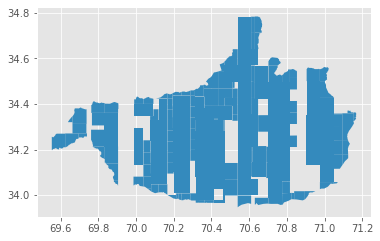

In [405]:
clipped_tiles.plot()

In [30]:
import os
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
import shutil

def reproject_rasters(folder_path, target_crs, destination_folder):
    """
    Checks the projection of raster files in a folder, and reprojects them if necessary.

    Parameters:
    folder_path (str): Path to the folder containing raster files.
    target_crs (str or dict): The target CRS (e.g., "EPSG:4326").
    destination_folder (str): Path to the folder where reprojected rasters will be saved.
    """
    os.makedirs(destination_folder, exist_ok=True)  # Ensure destination folder exists

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".tif", ".tiff")):  # Case-insensitive check
            raster_path = os.path.join(folder_path, filename)

            with rasterio.open(raster_path) as src:
                src_crs = src.crs

                if src_crs != target_crs:
                    print(f"Reprojecting {filename} from {src_crs} to {target_crs}")

                    # Calculate transformation
                    transform, width, height = calculate_default_transform(
                        src_crs, target_crs, src.width, src.height, *src.bounds
                    )

                    # Read the image data into memory to pass it to save_raster
                    clipped_image = src.read()

                    # Define metadata for the reprojected image
                    clipped_transform = transform
                    # file_name = f"reprojected_{os.path.splitext(filename)[0]}.tif"
                    # file_dest_path = destination_folder

                    file_name = raster_path.split("/")[-1].split(".")[0]
                    file_dest_path =destination_folder + "/" 
                    # Save the reprojected raster using save_raster
                    save_raster(
                        img=clipped_image,
                        number_of_bands=src.count,
                        transf=clipped_transform,
                        paths=file_dest_path,
                        tiff_name=file_name+".tif",
                        crs_img=target_crs
                    )
                    print(f"Saved reprojected file: {file_dest_path}{file_name}")

                else:
                    print(f"{filename} is already in the target CRS.")
                    dest_path = os.path.join(destination_folder, os.path.splitext(filename)[0] + ".tif")
                    shutil.copy2(raster_path, dest_path)
                    print(f"Copied file to: {dest_path}")       
    print("DONE!")

# Example usage:
# reproject_rasters("path/to/source_folder", "EPSG:4326", "path/to/destination_folder")


In [31]:
reproject_rasters(folder_path="/home/jovyan/work/imagery/afghanistan/kandahar_13082025", 
                  target_crs="EPSG:4326",
                  destination_folder="/home/jovyan/work/imagery/afghanistan/kandahar_130820256_4326")

Reprojecting 25JUL29062632-S3DS_R1C2-200009194726_01_P001.tif from EPSG:32641 to EPSG:4326
Saved reprojected file: /home/jovyan/work/imagery/afghanistan/kandahar_130820256_4326/25JUL29062632-S3DS_R1C2-200009194726_01_P001
Reprojecting 25JUL29062632-S3DS_R1C3-200009194726_01_P001.tif from EPSG:32641 to EPSG:4326
Saved reprojected file: /home/jovyan/work/imagery/afghanistan/kandahar_130820256_4326/25JUL29062632-S3DS_R1C3-200009194726_01_P001
Reprojecting 25JUL29062632-S3DS_R2C1-200009194726_01_P001.tif from EPSG:32641 to EPSG:4326
Saved reprojected file: /home/jovyan/work/imagery/afghanistan/kandahar_130820256_4326/25JUL29062632-S3DS_R2C1-200009194726_01_P001
Reprojecting 25JUL29062632-S3DS_R2C2-200009194726_01_P001.tif from EPSG:32641 to EPSG:4326
Saved reprojected file: /home/jovyan/work/imagery/afghanistan/kandahar_130820256_4326/25JUL29062632-S3DS_R2C2-200009194726_01_P001
Reprojecting 25JUL29062632-S3DS_R2C3-200009194726_01_P001.tif from EPSG:32641 to EPSG:4326
Saved reprojected fil

In [144]:
# test=rasterio.open("/home/jovyan/work/imagery/myanamar/after/extract_imagery/25MAR30040451-S3DS_R1C2-050312087010_01_P001.TIF")
# test.crs

In [30]:
import geopandas as gpd


gdf = gpd.read_file("/home/jovyan/work/predictions/afghanistan/nangarhar/nangarhar2025_B7/v2_better_imagery/geojson/predicted_buildings.geojson")
gdf.to_file("/home/jovyan/work/predictions/afghanistan/nangarhar/nangarhar2025_B7/v2_better_imagery/geojson/nang_2025_v2_buildings.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,


In [ ]:
import geopandas as gpd


gdf = gpd.read_file("/home/jovyan/work/predictions/afghanistan/Brian/geojson/predicted_buildings.geojson")
gdf.to_file("/home/jovyan/work/predictions/afghanistan/Brian/geojson/predicted_buildings.gpkg")